# Hourly appliance energy demand

Biniyam Berga

## Results at a glance

The cells below recompute metrics from the saved prediction rows. The headline model is selected on validation error, not test error. All results are historical experiments, not live forecasts.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from forecasting import load_data
from forecasting.evaluation import implementation_sha256
from forecasting.plots import set_style, comparison_plot, forecast_plot, error_plot

ROOT = Path.cwd()
DATASET = "energy"
result_dir = ROOT / "results" / DATASET
summary = json.loads((result_dir / "summary.json").read_text())
predictions = pd.read_csv(result_dir / "predictions.csv")
metrics = pd.read_csv(result_dir / "metrics.csv")
source_path = ROOT / "data" / ("appliances_hourly.csv" if DATASET == "energy" else "dc.csv")
assert hashlib.sha256(source_path.read_bytes()).hexdigest() == summary["input_sha256"]
assert implementation_sha256() == summary["implementation_sha256"]
data = load_data(source_path, DATASET)
set_style()
for horizon in summary["horizons"]:
    model = summary["selected_models"][str(horizon)]
    row = metrics.loc[(metrics.phase == "test") & (metrics.model == model) & (metrics.horizon == horizon)].iloc[0]
    print(f"{horizon} steps: {model}, MAE {row.mae:.4f} {summary['unit']}, {int(row.n)} forecasts, interval coverage {row.coverage:.1%}")

1 steps: drift, MAE 0.2419 kWh per hour, 26 forecasts, interval coverage 73.1%
6 steps: boosted, MAE 0.1863 kWh per hour, 26 forecasts, interval coverage 84.6%
24 steps: naive, MAE 0.1565 kWh per hour, 26 forecasts, interval coverage 96.2%


## Context and methods

The first 40% of observations seed the expanding training window. The following three 20% blocks are validation, interval calibration, and final test. Every model forecasts the same origins and horizons. Parameters are fixed in code. Validation chooses the model separately for each horizon; calibration fixes its error-band width.

### Key assumptions

- A forecast is issued after its origin observation becomes available.
- Refits can use earlier observed test values, but never future values. Test data do not select models or calibrate intervals.
- The 80% intervals use past absolute forecast errors. Time dependence and regime changes mean 80% future coverage is not guaranteed.
- One historical series does not establish production or trading performance.

To regenerate model outputs first: `python time_series_forecasting.py --dataset energy --output results/energy`. This notebook analyzes those outputs without fitting a second, different pipeline.

## Data

This study uses one Belgian household measured in early 2016. Six complete ten-minute readings are summed and divided by 1,000 to obtain hourly kWh. This is appliance energy, not total household energy or instantaneous power. Source: [UCI, Candanedo (2017), CC BY 4.0](https://doi.org/10.24432/C5VC8G).

In [2]:
print(f"{len(data):,} observations: {data.index.min()} to {data.index.max()}")
display(data.head(3))
display(pd.DataFrame(summary["splits"]).T[["start", "end", "rows", "n_origins"]])
assert not data.index.has_duplicates
assert data.index.is_monotonic_increasing
assert np.isfinite(data.y).all()

3,289 observations: 2016-01-11 17:00:00 to 2016-05-27 17:00:00


,y
timestamp,
2016-01-11 17:00:00,0.33
2016-01-11 18:00:00,1.06
2016-01-11 19:00:00,1.04


,start,end,rows,n_origins
training,2016-01-11T17:00:00,2016-03-06T11:00:00,1315,NaN
validation,2016-03-06T12:00:00,2016-04-02T21:00:00,658,26
calibration,2016-04-02T22:00:00,2016-04-30T07:00:00,658,26
test,2016-04-30T08:00:00,2016-05-27T17:00:00,658,26


## Results

### Independent metric check

MAE and RMSE are recomputed below from all saved prediction rows. MAPE is a percentage; zero actuals are excluded and counted separately.

In [3]:
for key, rows in predictions.groupby(["phase", "model", "horizon"]):
    phase, model, horizon = key
    saved = metrics.loc[(metrics.phase == phase) & (metrics.model == model) & (metrics.horizon == horizon)].iloc[0]
    error = rows.prediction - rows.actual
    assert np.isclose(np.abs(error).mean(), saved.mae)
    assert np.isclose(np.sqrt(np.square(error).mean()), saved.rmse)
    nonzero = rows.actual.ne(0)
    assert int(nonzero.sum()) == int(saved.mape_n)
    if nonzero.any():
        assert np.isclose((error[nonzero].abs() / rows.actual[nonzero].abs()).mean() * 100, saved.mape_pct)
print("Saved MAE, RMSE, MAPE, and denominators match every prediction group.")
display(metrics.loc[metrics.phase.eq("test"), ["model", "horizon", "n", "mae", "rmse", "mape_pct", "coverage"]].round(4))

Saved MAE, RMSE, MAPE, and denominators match every prediction group.


,model,horizon,n,mae,rmse,mape_pct,coverage
18,arima,1,26,0.2620,0.4738,34.6054,0.8077
19,arima,6,26,0.3099,0.4560,52.4394,0.8077
20,arima,24,26,0.1695,0.2484,33.2077,1.0000
21,boosted,1,26,0.2288,0.4062,31.0097,0.8462
22,boosted,6,26,0.1863,0.2965,29.6351,0.8462
23,boosted,24,26,0.2399,0.3141,50.7579,0.8462
24,drift,1,26,0.2419,0.4482,30.5363,0.7308
25,drift,6,26,0.3071,0.4527,50.6902,0.9231
26,drift,24,26,0.1569,0.2269,28.9988,0.9615
27,naive,1,26,0.2419,0.4482,30.5304,0.7308


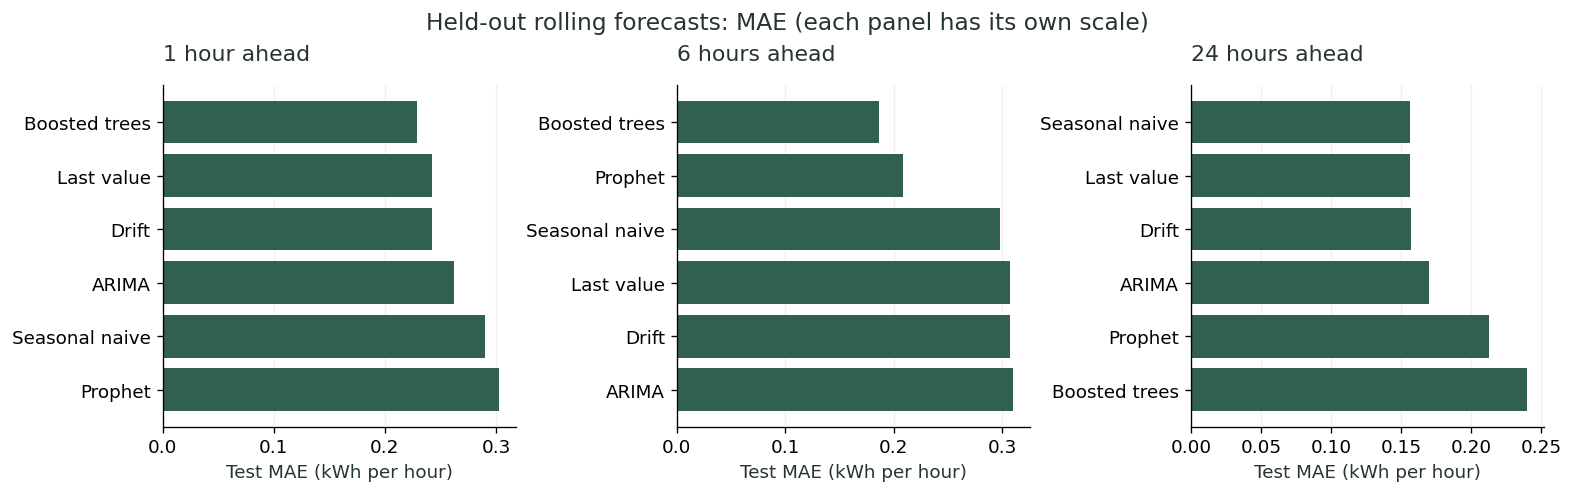

In [4]:
figure = comparison_plot(metrics, summary["horizons"], summary["unit"], summary["frequency"])
plt.show()

### Forecasts and uncertainty

The longest requested horizon is shown below. The band is calibrated before test and stays fixed. The lines connect separate rolling forecasts; they are not a single forecast path issued on one date.

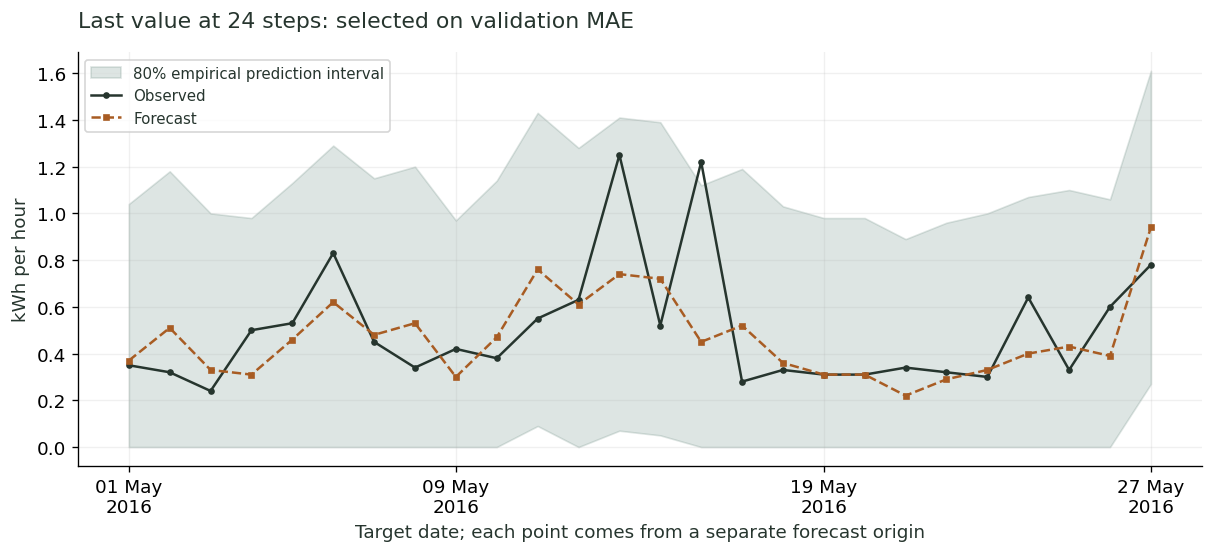

In [5]:
horizon = max(summary["horizons"])
figure = forecast_plot(predictions, summary, horizon)
plt.show()

### Where the selected model misses

The sign of an error distinguishes underprediction from overprediction. These observations describe this test period, not a causal explanation.

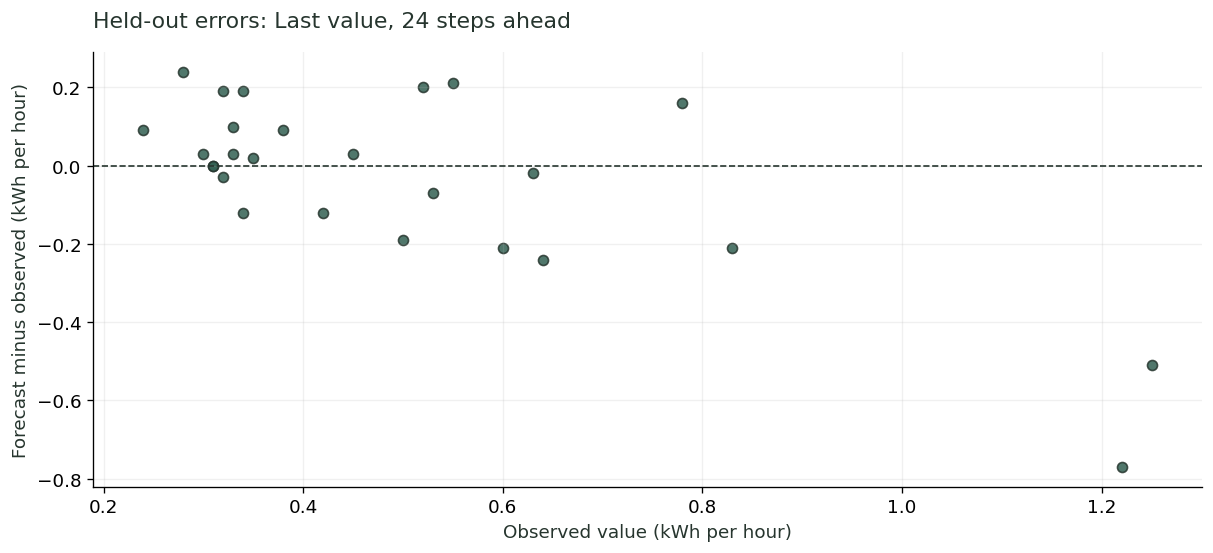

,origin,timestamp,actual,prediction,absolute_error
1190,2016-05-14 21:00:00,2016-05-15 21:00:00,1.22,0.45,0.77
1154,2016-05-12 19:00:00,2016-05-13 19:00:00,1.25,0.74,0.51
1208,2016-05-15 22:00:00,2016-05-16 22:00:00,0.28,0.52,0.24
1334,2016-05-23 05:00:00,2016-05-24 05:00:00,0.64,0.40,0.24
1028,2016-05-05 12:00:00,2016-05-06 12:00:00,0.83,0.62,0.21


In [6]:
figure = error_plot(predictions, summary, horizon)
plt.show()
model = summary["selected_models"][str(horizon)]
selected = predictions.loc[predictions.phase.eq("test") & predictions.model.eq(model) & predictions.horizon.eq(horizon)].copy()
selected["absolute_error"] = (selected.prediction - selected.actual).abs()
display(selected.nlargest(5, "absolute_error")[["origin", "timestamp", "actual", "prediction", "absolute_error"]].round(4))

## Takeaways

A model selected on validation can still lose to the last-value baseline during test. The comparison below reports that outcome without changing the selection. Larger models are useful only when the measured errors support them.

In [7]:
test = metrics.loc[metrics.phase.eq("test")]
for horizon in summary["horizons"]:
    model = summary["selected_models"][str(horizon)]
    chosen = test.loc[test.model.eq(model) & test.horizon.eq(horizon)].iloc[0]
    baseline = test.loc[test.model.eq("naive") & test.horizon.eq(horizon)].iloc[0]
    relative = 100 * (chosen.mae / baseline.mae - 1) if baseline.mae else np.nan
    print(f"{horizon} steps: {model} MAE differs from last-value baseline by {relative:+.1f}% (negative is better).")
for caveat in summary["limitations"]:
    print(f"- {caveat}")

1 steps: drift MAE differs from last-value baseline by +0.0% (negative is better).
6 steps: boosted MAE differs from last-value baseline by -39.3% (negative is better).
24 steps: naive MAE differs from last-value baseline by +0.0% (negative is better).
- Historical experiments, not live forecasts or trading recommendations.
- Fixed configurations compare model families, not exhaustive hyperparameter searches.
- Selection uses validation only. Test values are not used to choose models or interval widths.
- Later test forecasts may learn from earlier test observations once those observations are available.
- Calibration errors are serially dependent; nominal 80% intervals have no guaranteed coverage.
- Origins are sparse, so metrics do not describe forecasts issued at every possible timestamp.
- Development runs preceded a calendar-sampling correction; these historical results are not fresh external validation.
- MAPE excludes zero actuals; MASE excludes zero seasonal training scales, wi